In [270]:
from datetime import datetime
now = datetime.now()
print(f"Last updated: {now.month}/{now.day}/{now.year} {now.strftime('%I:%M%p').lstrip('0').lower()}")

Last updated: 5/6/2026 6:19pm


In [271]:
# Block 0 - Imports + Data Preparation

# Import pandas for data handling and analysis
import pandas as pd

# Load the Excel spreadsheet containing the raw reaction time data
df = pd.read_excel("Capstone Reaction Time.xlsx")

# Remove the extra header rows from the spreadsheet
# Row 0 contains Time of Day labels
# Row 1 contains condition labels
df = df.iloc[2:]

# Rename columns so they are easier to reference in Python
df.columns = [
    "Amna_Trial", "Amna_Baseline", "Amna_Caffeine", "Amna_Practice",
    "Matt_Trial", "Matt_Baseline", "Matt_Caffeine", "Matt_Practice",
    "Ben_Trial", "Ben_Baseline", "Ben_Caffeine", "Ben_Practice"
]

# Create an empty list to store cleaned participant data
long_data = []

# Define participant names
participants = ["Amna", "Matt", "Ben"]

# Define experiment conditions
conditions = ["Baseline", "Caffeine", "Practice"]

# Convert the spreadsheet from wide format to long format
# This creates a cleaner dataset for plotting and statistical analysis
for person in participants:
    for condition in conditions:

        # Create a temporary dataframe for each participant/condition pair
        temp = pd.DataFrame({
            "Participant": person,
            "Trial": df[f"{person}_Trial"],
            "Condition": condition,
            "Reaction_Time_ms": df[f"{person}_{condition}"]
        })

        # Add temporary dataframe to master list
        long_data.append(temp)

# Combine all temporary dataframes into one dataframe
clean_df = pd.concat(long_data, ignore_index=True)

# Convert Trial and Reaction Time columns to numeric values
# Invalid values (such as AVG rows) become NaN
clean_df["Trial"] = pd.to_numeric(clean_df["Trial"], errors="coerce")
clean_df["Reaction_Time_ms"] = pd.to_numeric(clean_df["Reaction_Time_ms"], errors="coerce")

# Remove rows containing NaN values
clean_df = clean_df.dropna(subset=["Trial", "Reaction_Time_ms"])

# Convert columns to proper numeric data types
clean_df["Trial"] = clean_df["Trial"].astype(int)
clean_df["Reaction_Time_ms"] = clean_df["Reaction_Time_ms"].astype(float)

# Preview cleaned dataset
clean_df.head()

,Participant,Trial,Condition,Reaction_Time_ms
0,Amna,1,Baseline,216.0
1,Amna,2,Baseline,215.0
2,Amna,3,Baseline,247.0
3,Amna,4,Baseline,289.0
4,Amna,5,Baseline,232.0


In [272]:
# Block 1 - Numerical Summaries

# Generate numerical summary statistics grouped by condition
summary = clean_df.groupby("Condition")["Reaction_Time_ms"].agg(
    Sample_Size="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Min="min",
    Max="max"
)

# Compute sample range
summary["Range"] = summary["Max"] - summary["Min"]

# Compute first quartile (Q1)
q1 = clean_df.groupby("Condition")["Reaction_Time_ms"].quantile(0.25)

# Compute third quartile (Q3)
q3 = clean_df.groupby("Condition")["Reaction_Time_ms"].quantile(0.75)

# Compute interquartile range (IQR)
summary["IQR"] = q3 - q1

# Display summary statistics table
summary

,Sample_Size,Mean,Median,Std_Dev,Min,Max,Range,IQR
Condition,,,,,,,,
Baseline,90,255.622222,249.5,37.935361,118.0,395.0,277.0,36.75
Caffeine,90,248.777778,245.5,32.679505,165.0,361.0,196.0,48.50
Practice,90,241.722222,242.5,23.042232,142.0,294.0,152.0,27.00


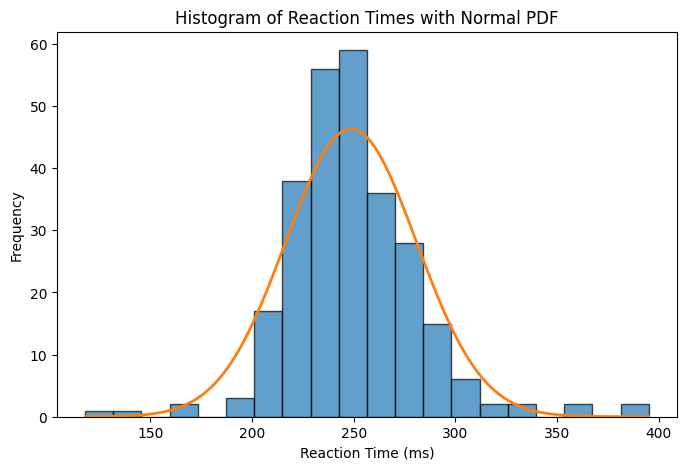

In [287]:
# Block 2 - Histogram with Overlaid Normal PDF

# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Store reaction time values
reaction_times = clean_df["Reaction_Time_ms"]

# Compute mean and standard deviation
mean = reaction_times.mean()
std = reaction_times.std()

# Create histogram using frequency counts
plt.figure(figsize=(8, 5))

counts, bins, patches = plt.hist(
    reaction_times,
    bins=20,
    edgecolor="black",
    alpha=0.7
)

# Create x-values for the normal curve
x = np.linspace(reaction_times.min(), reaction_times.max(), 200)

# Scale the normal PDF so it matches histogram frequency counts
bin_width = bins[1] - bins[0]
pdf_scaled = norm.pdf(x, mean, std) * len(reaction_times) * bin_width

# Plot scaled normal PDF
plt.plot(x, pdf_scaled, linewidth=2)

# Add labels and title
plt.title("Histogram of Reaction Times with Normal PDF")
plt.xlabel("Reaction Time (ms)")
plt.ylabel("Frequency")

# Display plot
plt.show()

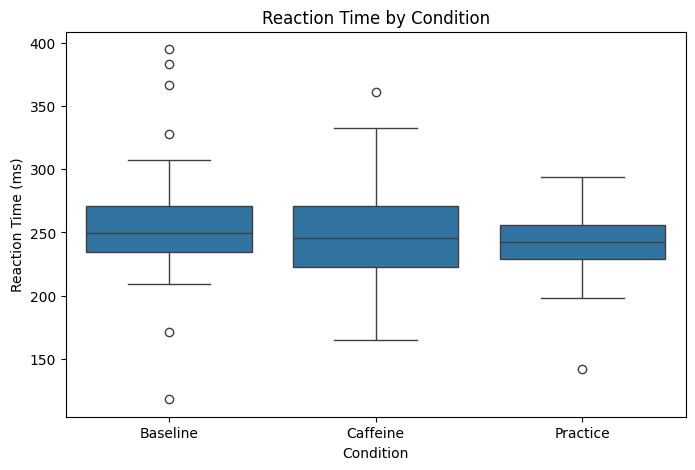

In [274]:
# Block 3 - Box Plot by Condition

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.boxplot(
    data=clean_df,
    x="Condition",
    y="Reaction_Time_ms"
)

plt.title("Reaction Time by Condition")
plt.xlabel("Condition")
plt.ylabel("Reaction Time (ms)")

plt.show()

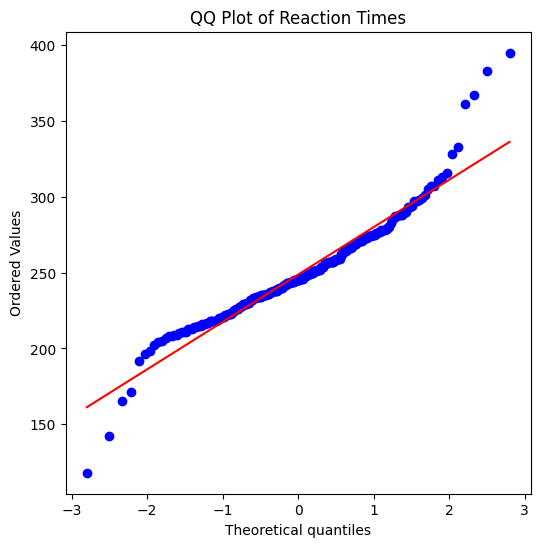

In [275]:
# Block 4 - QQ Plot

# Import scipy statistics module
import scipy.stats as stats

# Create QQ plot figure
plt.figure(figsize=(6,6))

# Generate normal probability plot
stats.probplot(reaction_times, dist="norm", plot=plt)

# Add title
plt.title("QQ Plot of Reaction Times")

# Display plot
plt.show()

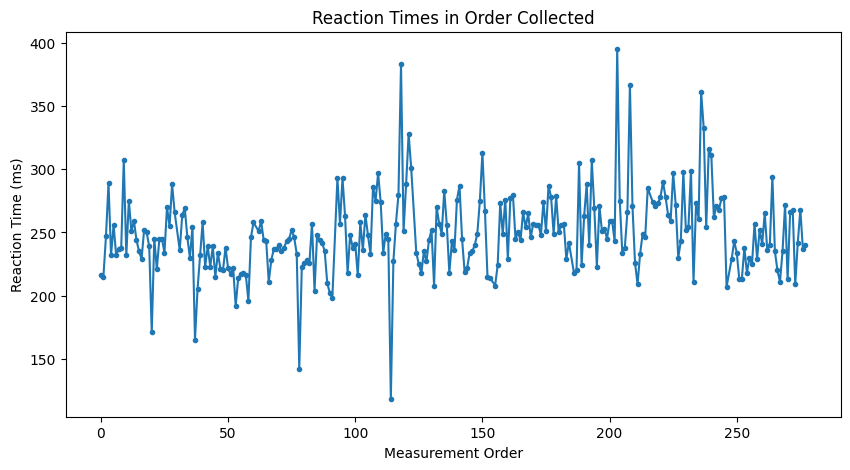

In [276]:
# Block 5 - Time Series Plot

# Create figure for time series plot
plt.figure(figsize=(10,5))

# Plot reaction times in order collected
plt.plot(
    clean_df.index,
    clean_df["Reaction_Time_ms"],
    marker='o',
    linestyle='-',
    markersize=3
)

# Add graph title and axis labels
plt.title("Reaction Times in Order Collected")
plt.xlabel("Measurement Order")
plt.ylabel("Reaction Time (ms)")

# Display plot
plt.show()

In [277]:
# Block 6 - Lognormal Distribution Fit

# Import lognormal distribution from scipy
from scipy.stats import lognorm

# Fit a lognormal distribution using Maximum Likelihood Estimation (MLE)
# floc=0 forces the location parameter to remain at 0
shape, loc, scale = lognorm.fit(reaction_times, floc=0)

# Display fitted distribution parameters
print("Lognormal Distribution Parameters")
print("---------------------------------")
print("Shape Parameter:", shape)
print("Location Parameter:", loc)
print("Scale Parameter:", scale)

Lognormal Distribution Parameters
---------------------------------
Shape Parameter: 0.13005090042090772
Location Parameter: 0
Scale Parameter: 246.6437880569187


In [278]:
# Block 7 - 95% Confidence Interval for Mean

# Import t-distribution from scipy
from scipy.stats import t

# Compute sample statistics
mean = reaction_times.mean()
std = reaction_times.std()
n = len(reaction_times)

# Set confidence level
confidence = 0.95

# Compute critical t-value
t_critical = t.ppf((1 + confidence) / 2, df=n-1)

# Compute margin of error
margin_error = t_critical * (std / np.sqrt(n))

# Compute confidence interval bounds
lower_bound = mean - margin_error
upper_bound = mean + margin_error

# Display confidence interval results
print("Confidence Interval Results")
print("---------------------------")
print("Sample Mean:", mean)
print("95% Confidence Interval:")
print(f"({lower_bound:.2f}, {upper_bound:.2f})")

Confidence Interval Results
---------------------------
Sample Mean: 248.7074074074074
95% Confidence Interval:
(244.85, 252.57)


In [279]:
# Block 8 - One-Sample t-Test

# Import the one-sample t-test function
from scipy.stats import ttest_1samp

# Perform a one-sample t-test
# H0: Mean reaction time = 250 ms
# H1: Mean reaction time ≠ 250 ms

t_stat, p_value = ttest_1samp(reaction_times, 250)

# Display results
print("One-Sample t-Test Results")
print("--------------------------")
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

# Determine statistical significance
if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
    print("The mean reaction time is significantly different from 250 ms.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("The mean reaction time is not significantly different from 250 ms.")

One-Sample t-Test Results
--------------------------
T-Statistic: -0.6594145557448201
P-Value: 0.510193716526016
Result: Fail to reject the null hypothesis.
The mean reaction time is not significantly different from 250 ms.


In [280]:
# Block 9 - Two-Sample t-Test (Baseline vs Caffeine)

# Import independent two-sample t-test
from scipy.stats import ttest_ind

# Separate baseline and caffeine reaction times
baseline = clean_df[clean_df["Condition"] == "Baseline"]["Reaction_Time_ms"]
caffeine = clean_df[clean_df["Condition"] == "Caffeine"]["Reaction_Time_ms"]

# Perform two-sample t-test
t_stat, p_value = ttest_ind(baseline, caffeine)

# Display results
print("Two-Sample t-Test Results")
print("--------------------------")
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

# Determine statistical significance
if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
    print("There is a significant difference between baseline and caffeine reaction times.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is no significant difference between baseline and caffeine reaction times.")

Two-Sample t-Test Results
--------------------------
T-Statistic: 1.2968169513994792
P-Value: 0.19637270013517322
Result: Fail to reject the null hypothesis.
There is no significant difference between baseline and caffeine reaction times.


In [281]:
# Block 10 - F-Test for Equal Variances

# Compute sample variances
var_baseline = baseline.var(ddof=1)
var_caffeine = caffeine.var(ddof=1)

# Compute F-statistic
f_stat = var_baseline / var_caffeine

# Degrees of freedom
df1 = len(baseline) - 1
df2 = len(caffeine) - 1

# Import F distribution
from scipy.stats import f

# Compute p-value
p_value = 2 * min(
    f.cdf(f_stat, df1, df2),
    1 - f.cdf(f_stat, df1, df2)
)

# Display results
print("F-Test for Equal Variances")
print("---------------------------")
print("F-Statistic:", f_stat)
print("P-Value:", p_value)

# Determine statistical significance
if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
    print("The variances are significantly different.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is no significant difference in variances.")

F-Test for Equal Variances
---------------------------
F-Statistic: 1.3475270858564365
P-Value: 0.16138893772598428
Result: Fail to reject the null hypothesis.
There is no significant difference in variances.


In [282]:
# Block 11 - Paired t-Test (Baseline vs Caffeine)

# Create matched baseline and caffeine values by participant and trial
paired_df = clean_df.pivot_table(
    index=["Participant", "Trial"],
    columns="Condition",
    values="Reaction_Time_ms"
).reset_index()

# Import paired t-test function
from scipy.stats import ttest_rel

# Perform paired t-test
t_stat, p_value = ttest_rel(
    paired_df["Baseline"],
    paired_df["Caffeine"]
)

# Display results
print("Paired t-Test Results")
print("----------------------")
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

# Determine statistical significance
if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
    print("There is a significant paired difference between baseline and caffeine reaction times.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is no significant paired difference between baseline and caffeine reaction times.")

Paired t-Test Results
----------------------
T-Statistic: 1.435859084650696
P-Value: 0.15454795219543863
Result: Fail to reject the null hypothesis.
There is no significant paired difference between baseline and caffeine reaction times.


In [283]:
# Block 12 - Participant Averages by Condition

# Create a summary table showing each participant's mean reaction time
# under each condition
participant_summary = clean_df.groupby(
    ["Participant","Condition"]
)["Reaction_Time_ms"].mean().reset_index()

# Pivot the table so conditions become columns
participant_summary_pivot = participant_summary.pivot(
    index="Participant",
    columns="Condition",
    values="Reaction_Time_ms"
)

# Add difference columns to show improvement or worsening
# Negative values mean reaction time got faster
participant_summary_pivot["Caffeine_vs_Baseline"] = (
    participant_summary_pivot["Caffeine"] - participant_summary_pivot["Baseline"]
)

participant_summary_pivot["Practice_vs_Baseline"] = (
    participant_summary_pivot["Practice"] - participant_summary_pivot["Baseline"]
)

# Display the participant-level summary
participant_summary_pivot

Condition,Baseline,Caffeine,Practice,Caffeine_vs_Baseline,Practice_vs_Baseline
Participant,,,,,
Amna,245.833333,227.633333,230.900000,-18.200000,-14.933333
Ben,261.066667,273.833333,239.100000,12.766667,-21.966667
Matt,259.966667,244.866667,255.166667,-15.100000,-4.800000


In [284]:
# Block 13 - Linear Regression

# Import linear regression tools
from scipy.stats import linregress

# Perform linear regression using trial number as predictor
slope, intercept, r_value, p_value, std_err = linregress(
    clean_df["Trial"],
    clean_df["Reaction_Time_ms"]
)

# Display regression results
print("Linear Regression Results")
print("--------------------------")
print("Slope:", slope)
print("Intercept:", intercept)
print("R-Squared:", r_value**2)
print("P-Value:", p_value)

Linear Regression Results
--------------------------
Slope: 0.17182054134223212
Intercept: 246.04418901660281
R-Squared: 0.002139784636134617
P-Value: 0.44906653996780715


In [288]:
# Block 14 - One-Way ANOVA

# Import one-way ANOVA function
from scipy.stats import f_oneway

# Separate reaction times by condition
baseline = clean_df[
    clean_df["Condition"] == "Baseline"
]["Reaction_Time_ms"]

caffeine = clean_df[
    clean_df["Condition"] == "Caffeine"
]["Reaction_Time_ms"]

practice = clean_df[
    clean_df["Condition"] == "Practice"
]["Reaction_Time_ms"]

# Perform one-way ANOVA
# H0: All group means are equal
# H1: At least one group mean is different

f_stat, p_value = f_oneway(
    baseline,
    caffeine,
    practice
)

# Display ANOVA results
print("One-Way ANOVA Results")
print("----------------------")
print("F-Statistic:", f_stat)
print("P-Value:", p_value)

# Determine statistical significance
if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
    print("At least one condition mean is significantly different.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is no significant difference between condition means.")

One-Way ANOVA Results
----------------------
F-Statistic: 4.29319857522739
P-Value: 0.014616390728384958
Result: Reject the null hypothesis.
At least one condition mean is significantly different.


In [286]:
# Block 15 - Export Final Dataset to CSV

# Export final formatted dataframe to CSV file
clean_df.to_csv("Reaction_Time_Data.csv", index=False)

# Confirmation message
print("Dataset exported successfully.")

Dataset exported successfully.
